In [23]:
import numpy as np
import pandas as pd
pd.options.display.float_format = "{:,.0f}".format
import matplotlib.pyplot as plt

In [24]:
dgs1 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS1", index_col=0, parse_dates=True, na_values=".")
dgs2 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS2", index_col=0, parse_dates=True, na_values=".")
dgs7 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS7", index_col=0, parse_dates=True, na_values=".")
dgs10 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10", index_col=0, parse_dates=True, na_values=".")
dff = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DFF", index_col=0, parse_dates=True, na_values=".")

In [25]:
yields = pd.concat([dgs1, dgs2, dgs7, dgs10, dff], axis=1).loc["2000-01-01":].dropna()
yields_m = yields.resample("ME").last()
yields_m["spread_bp"] = (yields_m["DGS10"] - yields_m["DGS2"]) * 100
yields_m.head()

C:\Users\guney\AppData\Local\Temp\ipykernel_4184\3218074976.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  yields = pd.concat([dgs1, dgs2, dgs7, dgs10, dff], axis=1).loc["2000-01-01":].dropna()


,DGS1,DGS2,DGS7,DGS10,DFF,spread_bp
observation_date,,,,,,
2000-01-31,6.30,6.61,6.75,6.68,5.87,7.0
2000-02-29,6.20,6.53,6.67,6.42,5.85,-11.0
2000-03-31,6.28,6.50,6.28,6.03,6.17,-47.0
2000-04-30,6.24,6.68,6.49,6.23,6.06,-45.0
2000-05-31,6.37,6.69,6.52,6.29,6.83,-40.0


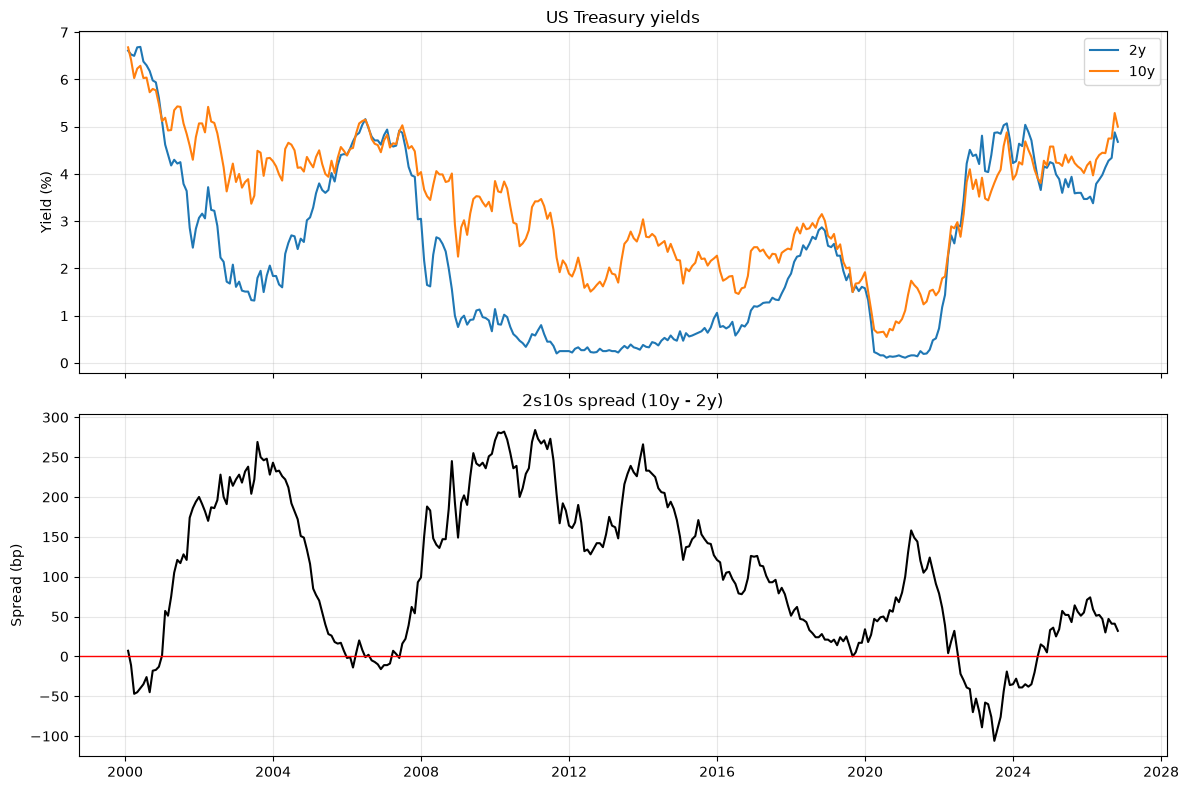

In [26]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(yields_m.index, yields_m["DGS2"], label="2y")
ax1.plot(yields_m.index, yields_m["DGS10"], label="10y")
ax1.set_ylabel("Yield (%)")
ax1.set_title("US Treasury yields")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(yields_m.index, yields_m["spread_bp"], color="black")
ax2.axhline(0, color="red", linewidth=1)
ax2.set_ylabel("Spread (bp)")
ax2.set_title("2s10s spread (10y - 2y)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
DV01 = 10_000
yields_m["spread_pnl"] = DV01 * yields_m["spread_bp"].diff()
yields_m["spread_pnl_cum"] = yields_m["spread_pnl"].cumsum()
yields_m["roll"] = (DV01 * ((yields_m["DGS2"] - yields_m["DGS1"]) - (yields_m["DGS10"] - yields_m["DGS7"]) / 3) * 100 / 12).shift(1)

In [28]:
y2 = yields_m["DGS2"] / 100
y10 = yields_m["DGS10"] / 100
r = yields_m["DFF"] / 100

yields_m["notional_2"] = DV01 / ((1 / y2) * (1 - 1 / (1 + y2 / 2) ** 4) * 1e-4)
yields_m["notional_10"] = DV01 / ((1 / y10) * (1 - 1 / (1 + y10 / 2) ** 20) * 1e-4)

yields_m["carry"] = ((yields_m["notional_2"] * (y2 - r) - yields_m["notional_10"] * (y10 - r)) / 12).shift(1)

In [29]:
HAIRCUT_2, HAIRCUT_10 = 0.02, 0.05
E0 = HAIRCUT_2 * yields_m["notional_2"].iloc[0] + HAIRCUT_10 * yields_m["notional_10"].iloc[0]

yields_m["carry_roll"] = yields_m["carry"] + yields_m["roll"]
yields_m["total_pnl"] = yields_m["spread_pnl"] + yields_m["carry_roll"]

pnl = yields_m.dropna(subset=["total_pnl"])
E0

np.float64(1777430.821433513)

In [30]:
def performance(series, base):
    """Stats for a monthly dollar P&L stream against `base` of capital.

    Financing is already netted inside `carry`, so `series / base` is an
    excess return and no further risk-free subtraction applies.
    """
    r = series / base
    equity = base + series.cumsum()
    return pd.Series({
        "ann. return": r.mean() * 12,
        "ann. volatility": r.std() * np.sqrt(12),
        "Sharpe": r.mean() / r.std() * np.sqrt(12),
        "max drawdown": (equity / equity.cummax() - 1).min(),
    })


performance(pnl["total_pnl"], E0)

ann. return        0.027154
ann. volatility    0.328619
Sharpe             0.082630
max drawdown      -0.508864
dtype: float64

In [31]:
COMPONENTS = {"spread": "spread_pnl", "carry + roll": "carry_roll",
              "roll": "roll", "carry": "carry", "total": "total_pnl"}

split = pd.DataFrame(
    {"cumulative $m": [pnl[c].sum() / 1e6 for c in COMPONENTS.values()],
     "ann. % of E0": [pnl[c].mean() * 12 / E0 for c in COMPONENTS.values()],
     "monthly sd $k": [pnl[c].std() / 1e3 for c in COMPONENTS.values()]},
    index=list(COMPONENTS),
)
split.round(3)

,cumulative $m,ann. % of E0,monthly sd $k
spread,0.250,0.005,171.882
carry + roll,1.041,0.022,36.929
roll,1.871,0.039,22.781
carry,-0.830,-0.017,18.434
total,1.291,0.027,168.615


In [32]:
pd.DataFrame({f"E0 = ${b / 1e6:.2f}m": performance(pnl["total_pnl"], b)
              for b in (E0, 3e6, 5e6, 10e6)})

,E0 = $1.78m,E0 = $3.00m,E0 = $5.00m,E0 = $10.00m
ann. return,0.027154,0.016088,0.009653,0.004826
ann. volatility,0.328619,0.194699,0.116820,0.058410
Sharpe,0.082630,0.082630,0.082630,0.082630
max drawdown,-0.508864,-0.421848,-0.329635,-0.213152


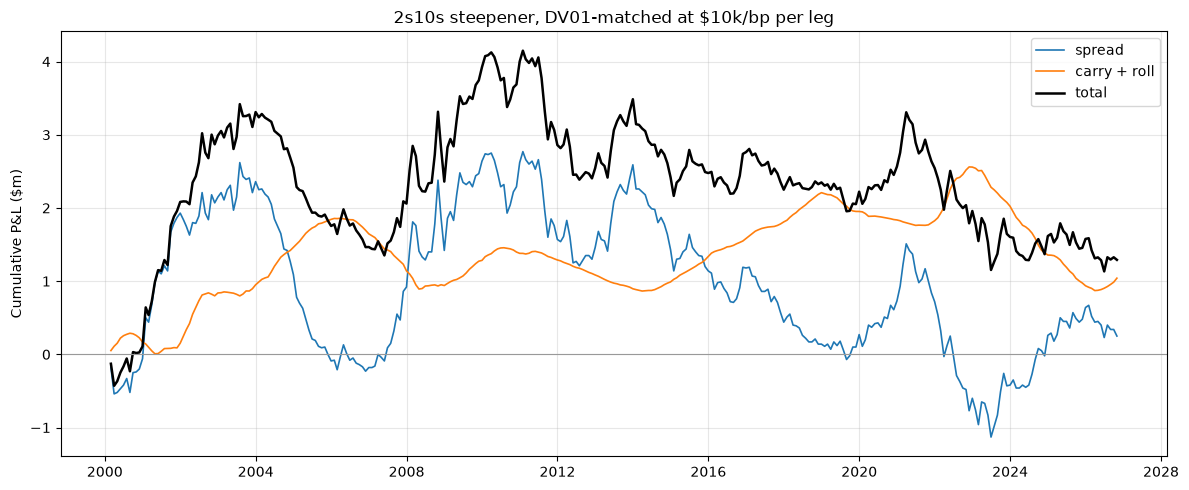

In [33]:
fig, ax = plt.subplots(figsize=(12, 5))

for label, col in [("spread", "spread_pnl"), ("carry + roll", "carry_roll"), ("total", "total_pnl")]:
    ax.plot(pnl.index, pnl[col].cumsum() / 1e6, label=label,
            color="black" if col == "total_pnl" else None,
            linewidth=1.8 if col == "total_pnl" else 1.2)

ax.axhline(0, color="0.6", linewidth=0.8)
ax.set_ylabel("Cumulative P&L ($m)")
ax.set_title("2s10s steepener, DV01-matched at $10k/bp per leg")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
yields_m[["spread_bp", "spread_pnl", "roll", "carry"]].tail(24)

,spread_bp,spread_pnl,roll,carry
observation_date,,,,
2024-11-30,5.0,-70000.0,-11111.111111,-23701.216796
2024-12-31,33.0,280000.0,-16388.888889,-15615.249053
2025-01-31,36.0,30000.0,4722.222222,-6132.343229
2025-02-28,25.0,-110000.0,1111.111111,-7447.692998
2025-03-31,34.0,90000.0,-10277.777778,-13952.198700
2025-04-30,57.0,230000.0,-15555.555556,-18202.751581
2025-05-31,52.0,-50000.0,-27500.000000,-30153.370963
2025-06-30,52.0,0.0,-24722.222222,-20065.020277
2025-07-31,43.0,-90000.0,-27222.222222,-25681.422812


In [35]:
(yields_m["carry"].dropna() < 0).mean()

np.float64(0.5887850467289719)